# BÀI THỰC HÀNH SỐ 2 - BÀI 5 (TRANG 26 - 27): HEART DISEASE
**Họ và tên:** Phạm Lê Anh Khoa  
**MSSV:** 6451071035

### Chuẩn bị: Import các thư viện cần thiết

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

### Câu 5a: Nhập dữ liệu đầu vào, tiền xử lý xóa dữ liệu trống và đổi tên các cột dữ liệu
Đổi tên 14 cột theo yêu cầu: `'age'`, `'sex'`, `'chest_pain_type'`, `'resting_blood_pressure'`, `'cholesterol'`, `'fasting_blood_sugar'`, `'rest_ecg'`, `'max_heart_rate_achieved'`, `'exercise_induced_angina'`, `'st_depression'`, `'st_slope'`, `'num_major_vessels'`, `'thalassemia'`, `'target'`

In [2]:
print("Phạm Lê Anh Khoa - 6451071035")

# Đọc dữ liệu từ file heart.csv
df = pd.read_csv('Dataset/heart.csv', na_values=['?', ' ?', '? '], skipinitialspace=True)

# Tiền xử lý: xóa dòng dữ liệu trống
df.dropna(inplace=True)

# Danh sách tên cột mới theo đúng yêu cầu đề bài
new_columns = [
    'age', 'sex', 'chest_pain_type', 'resting_blood_pressure', 'cholesterol',
    'fasting_blood_sugar', 'rest_ecg', 'max_heart_rate_achieved',
    'exercise_induced_angina', 'st_depression', 'st_slope',
    'num_major_vessels', 'thalassemia', 'target'
]
df.columns = new_columns

print(f"Số lượng mẫu dữ liệu sau khi làm sạch: {len(df)}")
df.info()

Phạm Lê Anh Khoa - 6451071035
Số lượng mẫu dữ liệu sau khi làm sạch: 303
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    int64  
 1   sex                      303 non-null    int64  
 2   chest_pain_type          303 non-null    int64  
 3   resting_blood_pressure   303 non-null    int64  
 4   cholesterol              303 non-null    int64  
 5   fasting_blood_sugar      303 non-null    int64  
 6   rest_ecg                 303 non-null    int64  
 7   max_heart_rate_achieved  303 non-null    int64  
 8   exercise_induced_angina  303 non-null    int64  
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    int64  
 11  num_major_vessels        303 non-null    int64  
 12  thalassemia              303 non-null    int64  
 13  target            

### Câu 3: Khảo sát độ tương đồng giữa các cột với nhau bằng công thức Pearson

Phạm Lê Anh Khoa - 6451071035


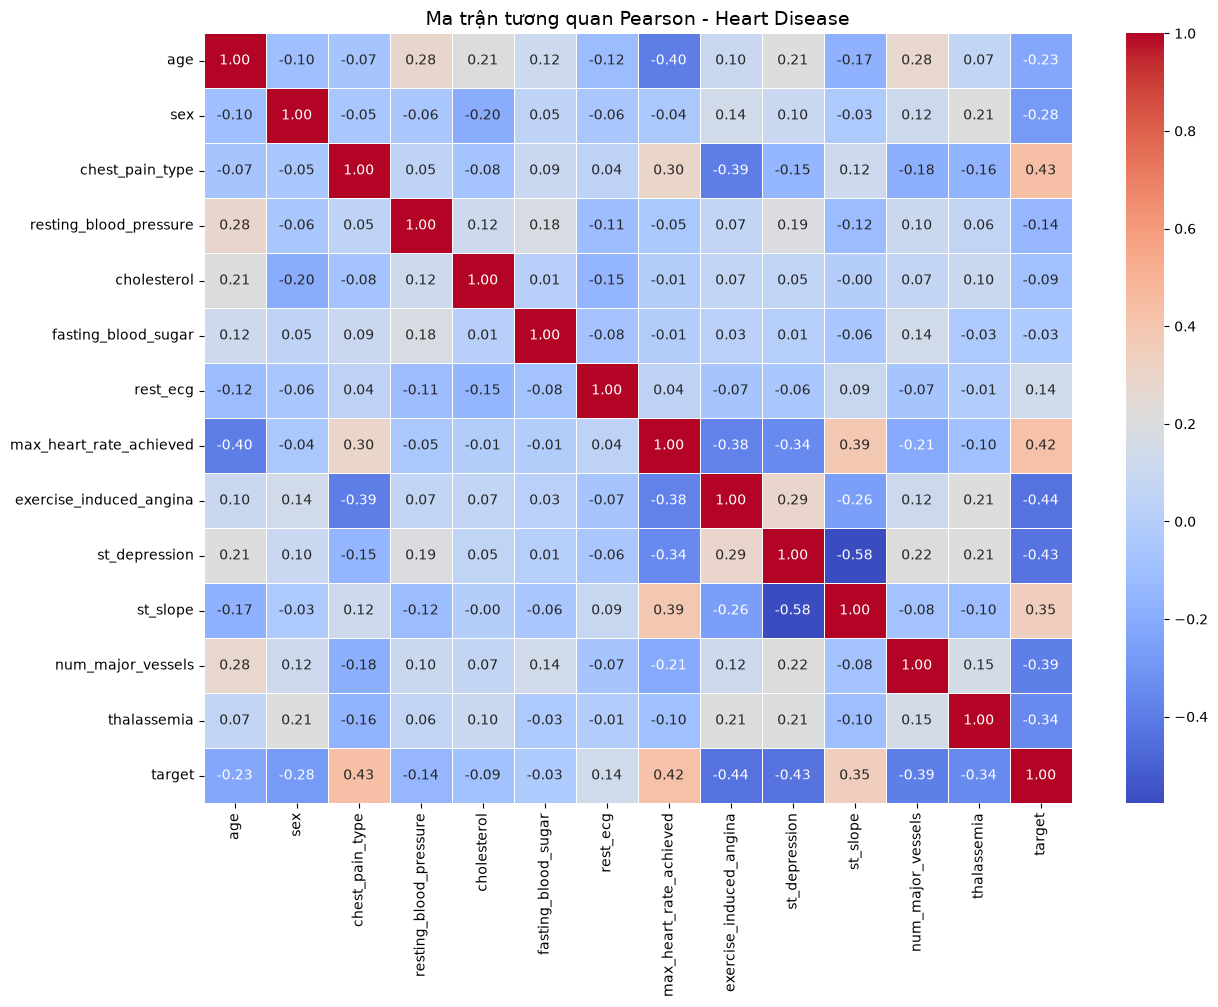

In [3]:
print("Phạm Lê Anh Khoa - 6451071035")

plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(method='pearson', numeric_only=True), annot=True, fmt=".2f", cmap='coolwarm', linewidths=.5)
plt.title("Ma trận tương quan Pearson - Heart Disease", size=14)
plt.show()

**Nhận xét:** Trong biểu đồ nhiệt, mức độ tương quan giữa các cặp biến độc lập đều nằm ở mức thấp và trung bình (không có cặp nào tương đồng quá cao trên 0.8). Do đó không cần thiết phải loại bỏ cột nào.

### Câu 4: Tách các cột dữ liệu thành hai phần (`features` và `labels`)

In [4]:
# Tách thuộc tính bình thường và thuộc tính quyết định 'target'
features = df.drop('target', axis=1)
labels = df['target']

### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [5]:
print("Phạm Lê Anh Khoa - 6451071035")

non_numeric = features.select_dtypes(exclude=['int64', 'float64', 'int32', 'float32']).columns
print("Các thuộc tính không phải dạng số:", list(non_numeric))

# Vì toàn bộ các đặc trưng đều đã ở dạng số nên features_onehot chính là features
features_onehot = features.copy()
features_onehot.head()

Phạm Lê Anh Khoa - 6451071035
Các thuộc tính không phải dạng số: []


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,rest_ecg,max_heart_rate_achieved,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện (70%) và kiểm thử (30%)

In [6]:
print("Phạm Lê Anh Khoa - 6451071035")

X_train, X_test, y_train, y_test = train_test_split(
    features_onehot, labels, test_size=0.3, random_state=42
)

print(f"Số lượng dữ liệu huấn luyện: {len(X_train)}")
print(f"Số lượng dữ liệu kiểm thử: {len(X_test)}")

Phạm Lê Anh Khoa - 6451071035
Số lượng dữ liệu huấn luyện: 212
Số lượng dữ liệu kiểm thử: 91


### Câu 7: Xây dựng cây ID3 dựa trên dữ liệu huấn luyện, kiểm thử bằng ma trận nhầm lẫn và biểu diễn cây

In [7]:
print("Phạm Lê Anh Khoa - 6451071035")

clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)

Phạm Lê Anh Khoa - 6451071035


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [8]:
print("Phạm Lê Anh Khoa - 6451071035")

id3_pred = clf_id3.predict(X_test)
id3_score = metrics.accuracy_score(y_test, id3_pred)
print(f"Accuracy: {id3_score:.4f} (~{id3_score*100:.2f}%)")
print("\nReport:")
print(metrics.classification_report(y_test, id3_pred))

Phạm Lê Anh Khoa - 6451071035
Accuracy: 0.7253 (~72.53%)

Report:
              precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Phạm Lê Anh Khoa - 6451071035


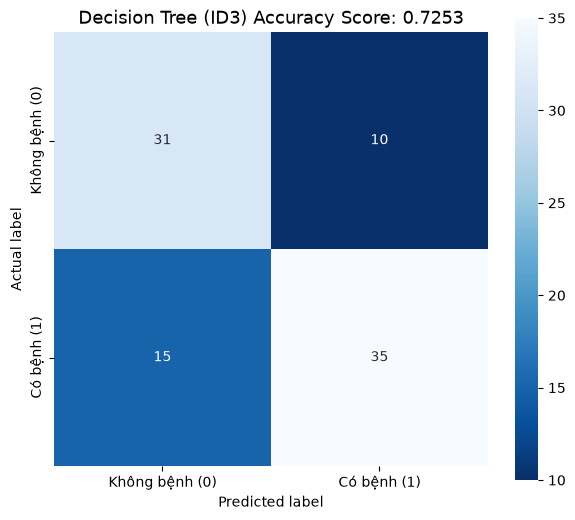

In [9]:
print("Phạm Lê Anh Khoa - 6451071035")

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
class_names = ['Không bệnh (0)', 'Có bệnh (1)']

plt.figure(figsize=(7, 6))
sns.heatmap(id3_cm, annot=True, fmt="d", square=True, cmap='Blues_r',
            xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (ID3) Accuracy Score: {id3_score:.4f}', size=13)
plt.show()

Phạm Lê Anh Khoa - 6451071035


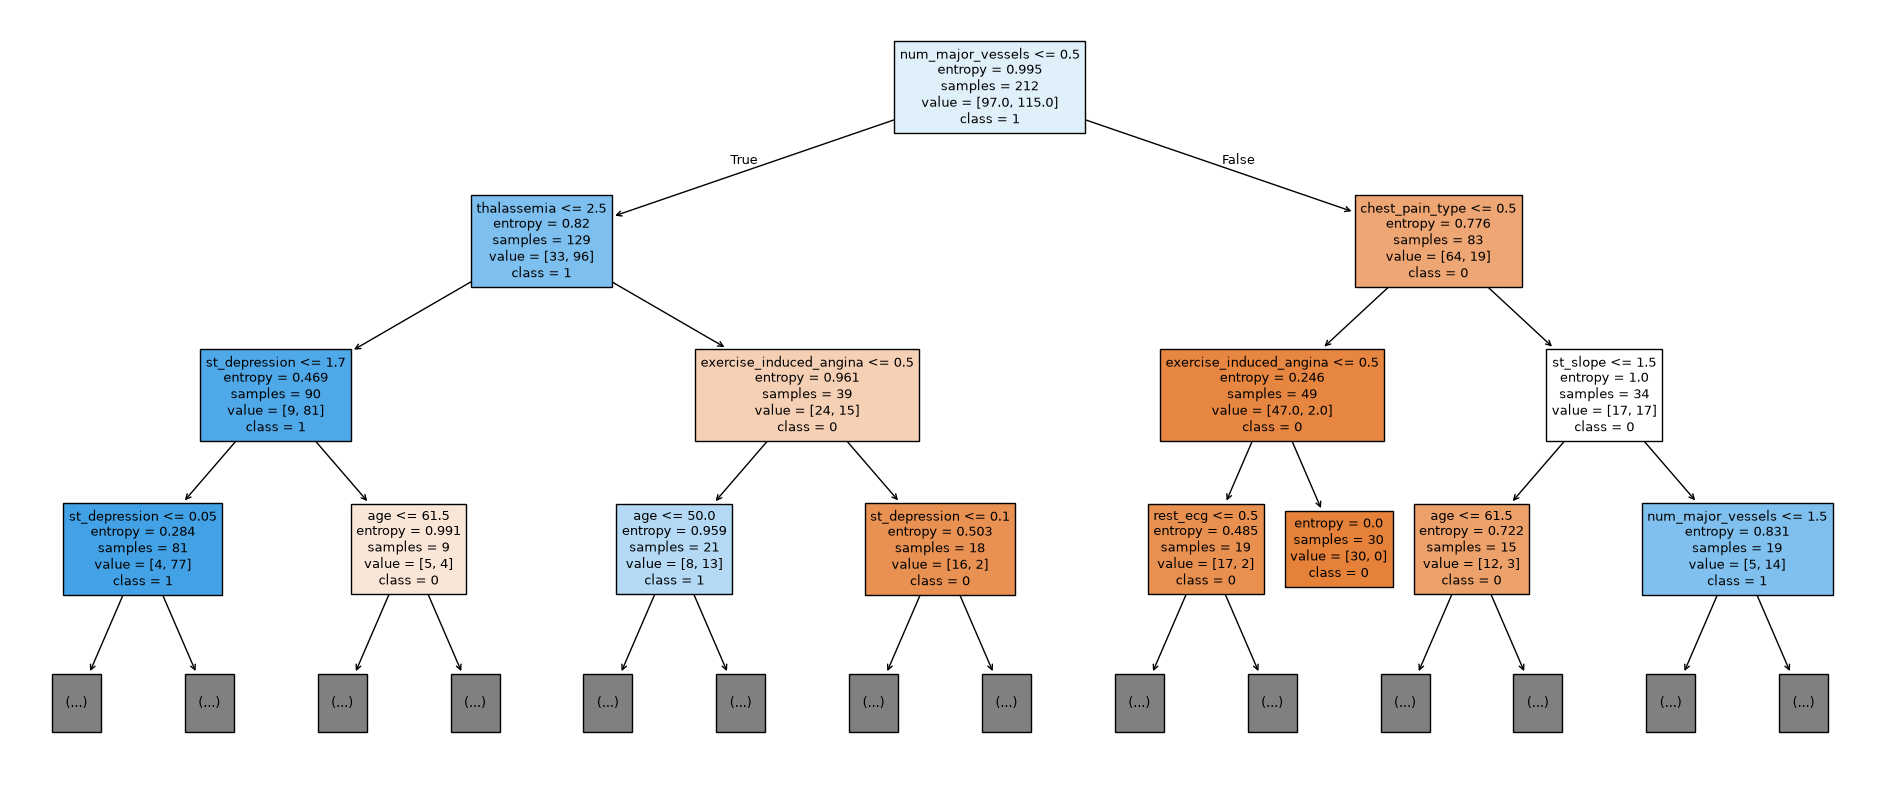

In [10]:
print("Phạm Lê Anh Khoa - 6451071035")

fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(
    clf_id3, 
    max_depth=3, 
    feature_names=features_onehot.columns, 
    class_names=['0', '1'], 
    filled=True, 
    fontsize=9
)
plt.savefig('heart_decision_tree_id3.png', dpi=100, bbox_inches='tight')
plt.show()

### Câu 8: Lặp lại Câu 7 đối với cây CART (`criterion='gini'`)

In [11]:
print("Phạm Lê Anh Khoa - 6451071035")

clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

Phạm Lê Anh Khoa - 6451071035


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [12]:
print("Phạm Lê Anh Khoa - 6451071035")

cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)
print(f"Accuracy: {cart_score:.4f} (~{cart_score*100:.2f}%)")
print("\nReport:")
print(metrics.classification_report(y_test, cart_pred))

Phạm Lê Anh Khoa - 6451071035
Accuracy: 0.7253 (~72.53%)

Report:
              precision    recall  f1-score   support

           0       0.67      0.76      0.71        41
           1       0.78      0.70      0.74        50

    accuracy                           0.73        91
   macro avg       0.73      0.73      0.72        91
weighted avg       0.73      0.73      0.73        91



Phạm Lê Anh Khoa - 6451071035


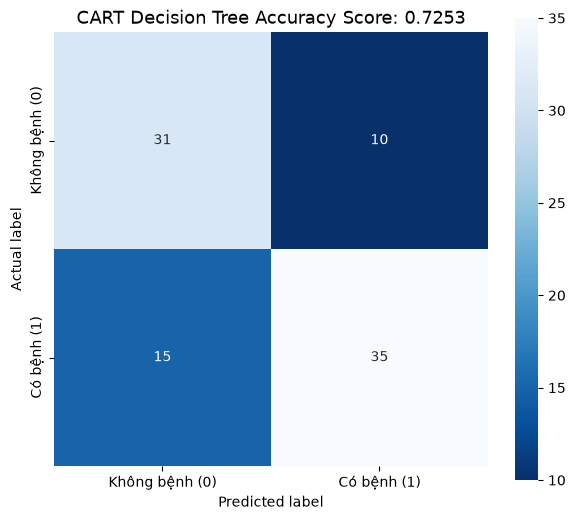

In [13]:
print("Phạm Lê Anh Khoa - 6451071035")

cart_cm = metrics.confusion_matrix(y_test, cart_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cart_cm, annot=True, fmt="d", square=True, cmap='Blues_r',
            xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'CART Decision Tree Accuracy Score: {cart_score:.4f}', size=13)
plt.show()

Phạm Lê Anh Khoa - 6451071035


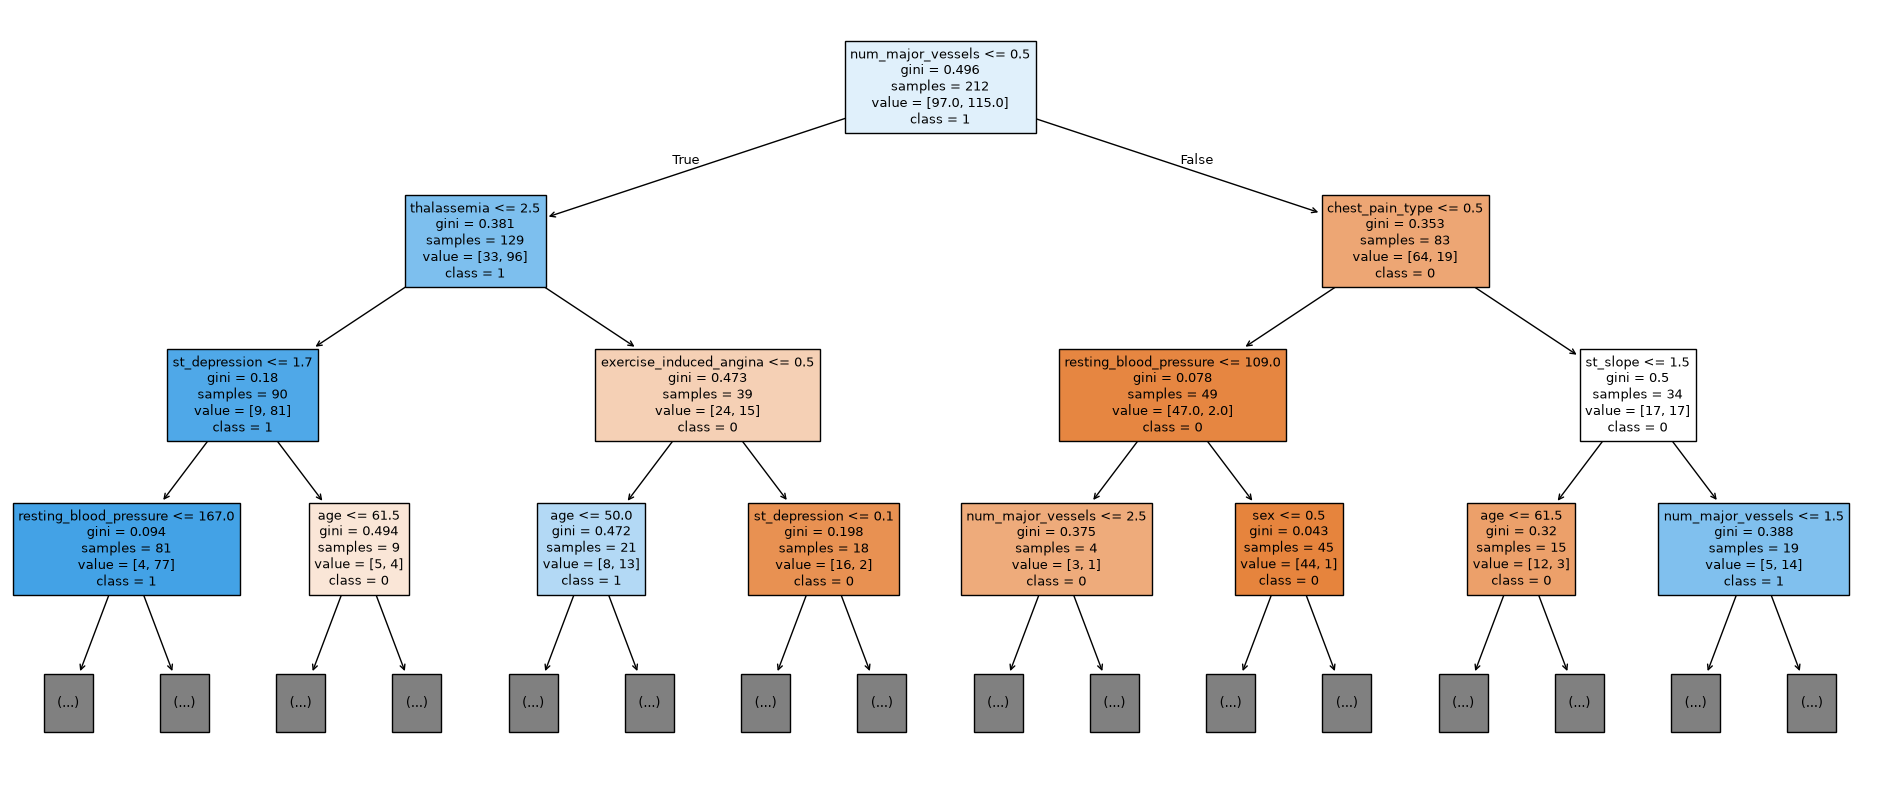

In [14]:
print("Phạm Lê Anh Khoa - 6451071035")

fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(
    clf_cart, 
    max_depth=3, 
    feature_names=features_onehot.columns, 
    class_names=['0', '1'], 
    filled=True, 
    fontsize=9
)
plt.savefig('heart_decision_tree_cart.png', dpi=100, bbox_inches='tight')
plt.show()

### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes và kiểm tra kết quả đạt được

In [15]:
print("Phạm Lê Anh Khoa - 6451071035")

gnb = GaussianNB()
gnb.fit(X_train, y_train)
bayes_pred = gnb.predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print(f"Accuracy: {bayes_score:.4f} (~{bayes_score*100:.2f}%)")
print("\nReport:")
print(metrics.classification_report(y_test, bayes_pred))

Phạm Lê Anh Khoa - 6451071035
Accuracy: 0.8352 (~83.52%)

Report:
              precision    recall  f1-score   support

           0       0.78      0.88      0.83        41
           1       0.89      0.80      0.84        50

    accuracy                           0.84        91
   macro avg       0.84      0.84      0.83        91
weighted avg       0.84      0.84      0.84        91



Phạm Lê Anh Khoa - 6451071035


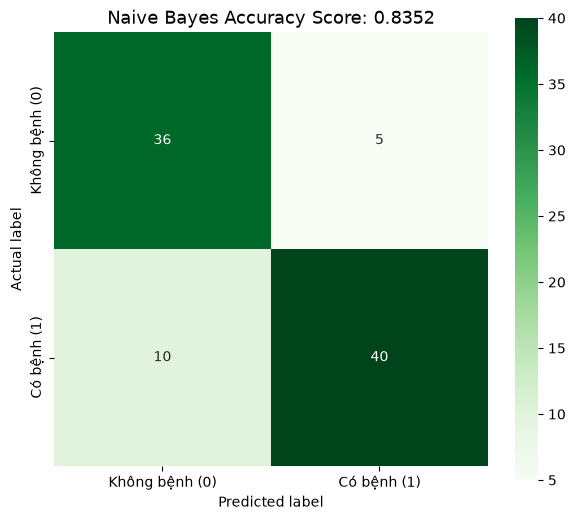

In [16]:
print("Phạm Lê Anh Khoa - 6451071035")

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(bayes_cm, annot=True, fmt="d", square=True, cmap='Greens',
            xticklabels=class_names, yticklabels=class_names)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naive Bayes Accuracy Score: {bayes_score:.4f}', size=13)
plt.show()

### Câu 10: So sánh kết quả của các mô hình trên

In [17]:
print("Phạm Lê Anh Khoa - 6451071035")

print("=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) TRÊN DỮ LIỆU HEART DISEASE ===")
print(f"1. Cây quyết định ID3 (Entropy) : {id3_score:.4f} (~{id3_score*100:.2f}%)")
print(f"2. Cây quyết định CART (Gini)   : {cart_score:.4f} (~{cart_score*100:.2f}%)")
print(f"3. Naïve Bayes (GaussianNB)     : {bayes_score:.4f} (~{bayes_score*100:.2f}%)")

Phạm Lê Anh Khoa - 6451071035
=== BẢNG SO SÁNH ĐỘ CHÍNH XÁC (ACCURACY) TRÊN DỮ LIỆU HEART DISEASE ===
1. Cây quyết định ID3 (Entropy) : 0.7253 (~72.53%)
2. Cây quyết định CART (Gini)   : 0.7253 (~72.53%)
3. Naïve Bayes (GaussianNB)     : 0.8352 (~83.52%)


**Nhận xét và so sánh các mô hình:**
1. **Về độ chính xác tổng thể (Accuracy):**
   - Mô hình **Naïve Bayes (GaussianNB)** cho kết quả vượt trội nhất đạt **83.52%**.
   - Cả hai mô hình Cây quyết định **ID3** và **CART** đạt độ chính xác tương đương nhau là **72.53%**.
2. **Đặc thù bài toán chẩn đoán y khoa (Heart Disease):**
   - Các chỉ số đo đạc lâm sàng (nhịp tim, huyết áp, cholesterol) phù hợp rất tốt với giả định phân phối chuẩn Gauss của Naïve Bayes.
   - Trong chẩn đoán y tế, chỉ số độ phủ (**Recall**) đối với lớp có bệnh (`target = 1`) có ý nghĩa sống còn để giảm thiểu tối đa trường hợp âm tính giả (bỏ sót bệnh nhân nguy kịch).